In [44]:
%load_ext autoreload
%autoreload 2
import copy
import gzip
import math
import os
import pickle
import re
from urllib.parse import urlsplit, urlunsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import predictor
import tqdm
import url_graph
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

ROOT = os.path.abspath('.')
PATH = next(p for p in (ROOT, os.path.join(ROOT, 'code')) if os.path.exists(os.path.join(p, 'graphs', 'graph_31444_nodes.gexf')))
GRAPH_PATH = os.path.join(PATH, 'graphs', 'graph_31444_nodes.gexf')
EMBEDDINGS_PATH = os.path.join(PATH, 'graphs', 'node2vec_embeddings.pkl.gz')
OUTPUT_PATH = os.path.join(PATH, 'graphs', 'evasion_f1.png')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [45]:
graph = url_graph.URLGraph.read_gexf(GRAPH_PATH)
with gzip.open(EMBEDDINGS_PATH, 'rb') as file:
    embeddings = pickle.load(file)
url_nodes = np.asarray([n for n, d in graph.get_graph().nodes(data=True) if d.get('type') == 'url' and d.get('malicious') is not None])
phishing_urls: list[str] = [n for n in url_nodes if graph.get_graph().nodes[n]['malicious'] is True] # type: ignore
benign_urls: list[str] = [n for n in url_nodes if graph.get_graph().nodes[n]['malicious'] is False] # type: ignore
print(f'Loaded {len(phishing_urls):,} phishing and {len(benign_urls):,} benign URLs.')

[nltk_data] Downloading package stopwords to /home/kit-
[nltk_data]     matthewson/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Loaded 4,977 phishing and 4,978 benign URLs.


In [46]:
def replace_domain(url, replacement_domain):
    has_scheme = bool(urlsplit(url).scheme)
    parts = urlsplit(url if has_scheme else f'//{url}')
    replaced = urlunsplit(parts._replace(netloc=replacement_domain))
    return replaced if has_scheme else replaced[2:]


def add_evasive_url(g, original_url, evasive_url, embedding_map):
    node = url_graph.url_to_node_name(evasive_url)
    g.add_node(node, type='url', malicious=None)
    embedding_map[node] = embedding_map[url_graph.url_to_node_name(original_url)]
    parts = urlsplit(evasive_url if urlsplit(evasive_url).scheme else f'//{evasive_url}')
    values = [parts.hostname, parts.path, parts.query]
    tokens = set()
    for value, pattern in zip(values, (r'[.]', r'[/.!&,#$%;&:]', r'[=&]')):
        if value:
            tokens.update(word for word in re.split(pattern, value) if word)
    for entity in {url_graph.clean_text(value) for value in tokens if value}:
        if g.has_node(entity):
            g.add_edge(node, entity)


def url_features(url):
    url = str(url)
    letters = sum(char.isalpha() for char in url)
    digits = sum(char.isdigit() for char in url)
    special = sum(not char.isalnum() for char in url)
    counts = {char: url.count(char) for char in './-@:?!=_&%#;'}
    probabilities = [url.count(char) / len(url) for char in set(url)]
    entropy = -sum(p * math.log2(p) for p in probabilities)
    tokens = re.findall(r'[a-z0-9]+', url.lower())
    return [len(url), len(tokens), len(url.split('.')), letters, digits, special,
            digits / max(len(url), 1), special / max(len(url), 1), entropy,
            int('@' in url), int('//' in url[8:]), int('https' in url.lower()),
            int(any(word in url.lower() for word in ('login', 'verify', 'secure', 'account'))),
            counts['.'], counts['-'], counts['/'], counts['?'], counts['='], counts['&']]


def random_forest_predictions(urls, labels, tested_urls):
    model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight='balanced')
    model.fit(np.asarray([url_features(url) for url in urls]), labels)
    return model.predict(np.asarray([url_features(url) for url in tested_urls]))


def polonium_predictions(g, tested_urls, observed_urls):
    """Run the graph-only POL baseline used in the baseline notebook."""
    nodes = list(g.nodes)
    index = {node: i for i, node in enumerate(nodes)}
    beliefs = np.full((len(nodes), 2), 0.5)
    observed = set(observed_urls)
    for node in observed:
        beliefs[index[node]] = [1.0, 0.0] if g.nodes[node]['malicious'] is False else [0.0, 1.0]
    compatibility = np.asarray([[0.9, 0.1], [0.1, 0.9]])
    for _ in range(5):
        updated = beliefs.copy()
        for node in nodes:
            if node in observed:
                continue
            neighbours = list(g.neighbors(node))
            if neighbours:
                messages = [compatibility @ beliefs[index[neighbour]] for neighbour in neighbours]
                updated[index[node]] = np.mean(messages, axis=0)
                updated[index[node]] /= updated[index[node]].sum()
        beliefs = updated
    return [int(beliefs[index[url], 1] >= beliefs[index[url], 0]) for url in tested_urls]


def cross_validated_baseline_f1(g, tested_phishing):
    cv_url_nodes = np.asarray(url_nodes)
    labels = np.asarray([int(graph.get_graph().nodes[node].get('malicious', False)) for node in cv_url_nodes])
    phishing_replacements = dict(zip(phishing_urls, tested_phishing))
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    rf_scores = []
    pol_scores = []
    for train, test in splitter.split(cv_url_nodes, labels):
        train_urls = cv_url_nodes[train]
        test_original_urls = cv_url_nodes[test]
        test_urls = [phishing_replacements.get(url, url) for url in test_original_urls]
        rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight='balanced')
        rf.fit(np.asarray([url_features(url) for url in train_urls]), labels[train])
        rf_scores.append(f1_score(labels[test], rf.predict(np.asarray([url_features(url) for url in test_urls])), zero_division=0))
        pol_predictions = polonium_predictions(g, test_urls, train_urls)
        pol_scores.append(f1_score(labels[test], pol_predictions, zero_division=0))
    return float(np.mean(pol_scores)), float(np.mean(rf_scores))


def run_evasion_experiment(ratios, random_state=42):
    rng = np.random.default_rng(random_state)
    replacements = [str(rng.choice(benign_urls)) for _ in phishing_urls]
    labels = [1] * len(phishing_urls) + [0] * len(benign_urls)
    scores = []
    
    for ratio in tqdm.tqdm(ratios, desc='Evasion experiment', unit='ratio', ncols=80, colour='green'):        
        g = copy.deepcopy(graph.get_graph())
        
        embedding_map = dict(embeddings)
        tested_phishing: list[str] = list(phishing_urls)
        
        for index, original_url in enumerate(phishing_urls[:round(ratio * len(phishing_urls))]):
            evasive_url = replace_domain(original_url, replacements[index])
            add_evasive_url(g, original_url, evasive_url, embedding_map)
            tested_phishing[index] = url_graph.url_to_node_name(evasive_url)
            
        model_graph = url_graph.URLGraph.__new__(url_graph.URLGraph)
        model_graph._graph = g
        
        model = predictor.Predictor(model_graph, embedding_map)
        model.train(output=False)
        
        tested_urls = tested_phishing + benign_urls
        predictions = [model.predict(url) for url in tested_urls]
        
        pol_f1, rf_f1 = cross_validated_baseline_f1(g, tested_phishing)
        
        scores.append({
            'evaded_percent': ratio * 100,
            'predictor_f1': f1_score(labels, predictions, zero_division=0),
            'polonium_f1': pol_f1,
            'random_forest_f1': rf_f1,
        })
        
    return pd.DataFrame(scores)

results = run_evasion_experiment(np.linspace(0, .2, 10))
display(results.round(3))

Evasion experiment: 100%|████████████████████| 10/10 [07:00<00:00, 42.04s/ratio]


,evaded_percent,predictor_f1,polonium_f1,random_forest_f1
0,0.000,0.965,0.906,0.818
1,2.222,0.962,0.897,0.813
2,4.444,0.955,0.890,0.810
3,6.667,0.955,0.882,0.807
4,8.889,0.952,0.873,0.804
5,11.111,0.952,0.866,0.801
6,13.333,0.951,0.859,0.797
7,15.556,0.945,0.850,0.793
8,17.778,0.941,0.842,0.791
9,20.000,0.937,0.835,0.788


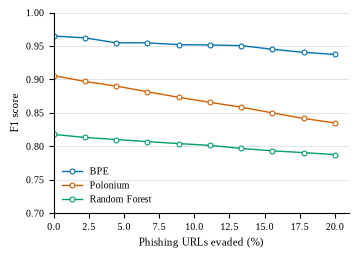

Saved graph to /home/kit-matthewson/Documents/exeter/masters/coursework/systems/code/graphs/evasion_f1.png


In [54]:
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Liberation Serif', 'Times New Roman', 'Times', 'DejaVu Serif'], 'font.size': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7, 'axes.linewidth': 0.8})
fig, ax = plt.subplots(figsize=(3.5, 2.5))
styles = {
    'predictor_f1': {'label': 'BPE', 'color': '#0072B2'},
    'polonium_f1':{'label': 'Polonium', 'color': '#D55E00'},
    'random_forest_f1': {'label': 'Random Forest', 'color': '#009E73'},
}
for column, style in styles.items():
    ax.plot(results['evaded_percent'], results[column], color=style['color'], linewidth=1.0, markersize=3.5, markerfacecolor='white', markeredgewidth=0.8, label=style['label'], linestyle='-', marker='o')
ax.set_xlabel('Phishing URLs evaded (%)')
ax.set_ylabel('F1 score')
ax.set_xlim(0, 21)
ax.set_ylim(0.7, 1)
ax.legend(frameon=False, loc='best', fontsize=7)
ax.grid(axis='y', color='0.85', linewidth=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout(pad=0.5)
fig.savefig(OUTPUT_PATH, dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved graph to {OUTPUT_PATH}')

In [53]:
f1_columns = ['predictor_f1', 'polonium_f1', 'random_forest_f1']
baseline_f1 = results.loc[results['evaded_percent'].eq(0), f1_columns].iloc[0]
decrease_df = results[['evaded_percent']].copy()
decrease_df[f1_columns] = baseline_f1.to_numpy() - results[f1_columns]
decrease_df = decrease_df.rename(columns={column: f'{column}_decrease' for column in f1_columns})
display(decrease_df.round(3))

,evaded_percent,predictor_f1_decrease,polonium_f1_decrease,random_forest_f1_decrease
0,0.000,0.000,0.000,0.000
1,2.222,0.003,0.009,0.005
2,4.444,0.010,0.016,0.008
3,6.667,0.010,0.024,0.011
4,8.889,0.013,0.032,0.014
5,11.111,0.013,0.040,0.016
6,13.333,0.014,0.047,0.021
7,15.556,0.020,0.056,0.025
8,17.778,0.024,0.064,0.027
9,20.000,0.028,0.071,0.030
